In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Mutation": root / "Mutation",
    "Crossover_95": root / "Crossover",
}
dataframes=[]
for source_name, folder in sources.items():
    if source_name == "Crossover_95":
        matching_folders = [
            path for path in folder.rglob("*")
            if path.is_dir() and path.name.endswith("95")
        ]
        for path in matching_folders:
            print(path.relative_to(root))
        csv_files = sorted({
            csv_file
            for matching_folder in matching_folders
            for csv_file in matching_folder.rglob("*.csv")
        })
    else:
        csv_files = sorted(folder.rglob("*.csv"))
    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

Crossover\Normal\Normal_acak_3_95
Crossover\Normal\Normal_Acak_4_95
Crossover\Normal\Normal_klaster_2_95
Crossover\Normal\Normal_labirin_2_95
Crossover\Small\Small_acak_3_95
Crossover\Small\Small_acak_4_95
Crossover\Small\Small_klaster_2_95
Crossover\Small\Small_labirin_2_95
Crossover\Tiny\Tiny_acak_3_95
Crossover\Tiny\Tiny_acak_4_95
Crossover\Tiny\Tiny_klaster_2_95
Crossover\Tiny\Tiny_labirin_2_95


In [3]:
df_All_Mutation_summary=(df_all.groupby(["grid_rows", "pm", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
))
display(df_All_Mutation_summary)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.507778,2.500000,2.600000,0.026932,90
1,10,0.01,Maze,3.335185,3.333333,3.500000,0.017568,90
2,10,0.01,Random,2.593717,2.416667,2.928571,0.152679,180
3,10,0.03,Cluster,2.506667,2.500000,2.600000,0.025084,90
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,90
5,10,0.03,Random,2.590807,2.416667,2.785714,0.153160,180
6,10,0.05,Cluster,2.514444,2.500000,2.600000,0.035351,90
7,10,0.05,Maze,3.337037,3.333333,3.500000,0.024705,90
8,10,0.05,Random,2.597884,2.416667,2.857143,0.157586,180
9,20,0.01,Cluster,4.794595,4.783784,4.837838,0.015587,90


In [4]:
table_random = (
    df_All_Mutation_summary[df_All_Mutation_summary["map_type"] == "Random"]
    .sort_values("pm")
)

display(table_random)
table_maze = (
    df_All_Mutation_summary[df_All_Mutation_summary["map_type"] == "Maze"]
    .sort_values("pm")
)

display(table_maze)
table_cluster = (
    df_All_Mutation_summary[df_All_Mutation_summary["map_type"] == "Cluster"]
    .sort_values("pm")
)

display(table_cluster)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.01,Random,2.593717,2.416667,2.928571,0.152679,180
11,20,0.01,Random,6.250840,6.025000,6.564103,0.217712,180
20,40,0.01,Random,6.703606,6.525641,7.050000,0.109984,180
5,10,0.03,Random,2.590807,2.416667,2.785714,0.153160,180
23,40,0.03,Random,6.681404,6.512821,6.918750,0.107754,180
14,20,0.03,Random,6.248020,6.025000,6.512821,0.216950,180
8,10,0.05,Random,2.597884,2.416667,2.857143,0.157586,180
17,20,0.05,Random,6.247041,6.025000,6.512821,0.217133,180
26,40,0.05,Random,6.667225,6.512821,6.912500,0.106084,180


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.01,Maze,3.335185,3.333333,3.500000,0.017568,90
10,20,0.01,Maze,6.814245,6.794872,6.871795,0.020452,90
19,40,0.01,Maze,6.942759,6.848276,7.179310,0.063734,90
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,90
22,40,0.03,Maze,6.906207,6.834483,7.137931,0.050030,90
13,20,0.03,Maze,6.812821,6.794872,6.846154,0.014097,90
7,10,0.05,Maze,3.337037,3.333333,3.500000,0.024705,90
16,20,0.05,Maze,6.809402,6.794872,6.846154,0.015399,90
25,40,0.05,Maze,6.885824,6.834483,7.124138,0.045136,90


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.507778,2.500000,2.600000,0.026932,90
9,20,0.01,Cluster,4.794595,4.783784,4.837838,0.015587,90
18,40,0.01,Cluster,5.536344,5.451613,5.754839,0.062440,90
3,10,0.03,Cluster,2.506667,2.500000,2.600000,0.025084,90
21,40,0.03,Cluster,5.491541,5.445161,5.600000,0.031501,90
12,20,0.03,Cluster,4.793093,4.783784,4.837838,0.015246,90
6,10,0.05,Cluster,2.514444,2.500000,2.600000,0.035351,90
15,20,0.05,Cluster,4.788589,4.783784,4.810811,0.010391,90
24,40,0.05,Cluster,5.484946,5.445161,5.651613,0.037771,90


In [5]:
df_All_Mutation_summary["rank_mean_cost"] = (
    df_All_Mutation_summary
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_All = (
    df_All_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_All)

,pm,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,0.05,1.666667,5.036932,0.072173,9
1,0.03,1.666667,5.040433,0.068202,9
0,0.01,2.666667,5.053230,0.076343,9


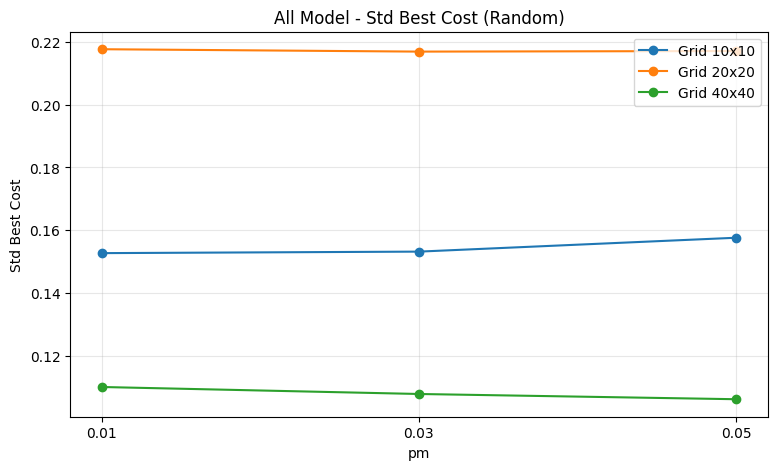

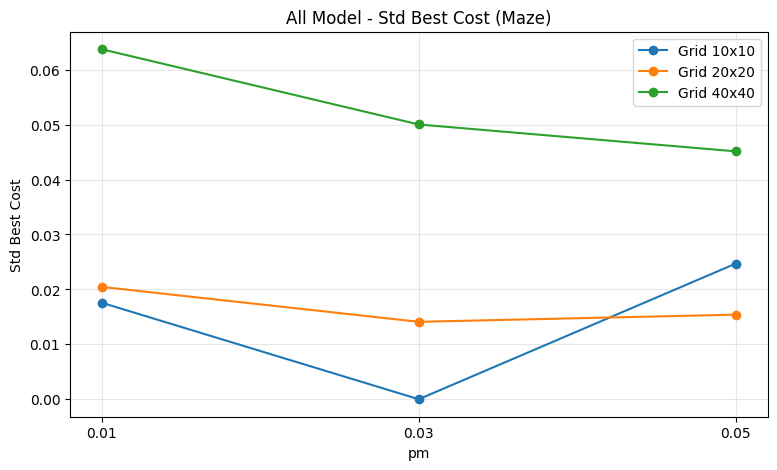

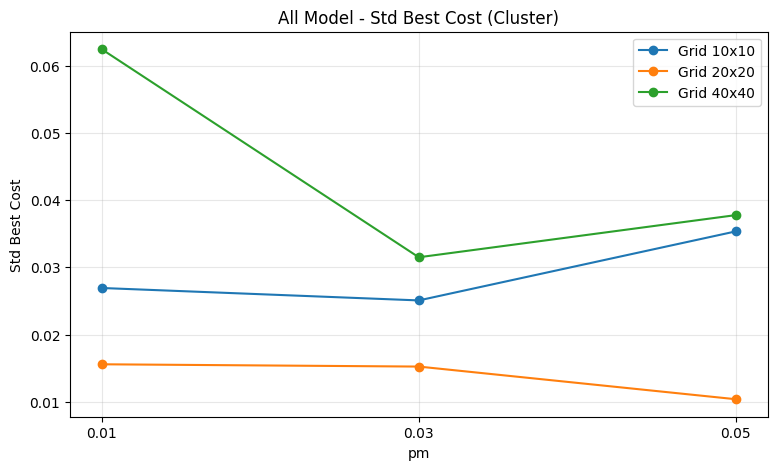

In [6]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = df_All_Mutation_summary[
        df_All_Mutation_summary["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pm")
        )

        plt.plot(
            data_size["pm"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"All Model - Std Best Cost ({map_type})")
    plt.xlabel("pm")
    plt.ylabel("Std Best Cost")
    plt.xticks(sorted(data["pm"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [7]:
#rank std cost
df_All_Mutation_summary["rank_std_cost"] = (
    df_All_Mutation_summary
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_All_std = (
    df_All_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_rank_std", "avg_std_cost"])
)

print(avg_rank_All_std)


     pm  avg_rank_std  avg_std_cost  jumlah_kombinasi
1  0.03      1.444444      0.068202                 9
2  0.05      2.000000      0.072173                 9
0  0.01      2.555556      0.076343                 9


In [9]:
summary_All_time=(df_all.groupby(["grid_rows","pm", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_All_time)
avg_time_by_population_All = (
    summary_All_time.groupby("pm", as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values("avg_execTime")
)
display(avg_time_by_population_All)
summary_time_pivot = summary_All_time.pivot(
    index=["grid_rows", "pm"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_All_time.groupby(["map_type", "pm"], as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pm,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.01,Cluster,40.311111,10,465,90.608014,90
1,10,0.01,Maze,37.888889,8,577,104.534543,90
2,10,0.01,Random,43.038889,9,496,90.768683,180
3,10,0.03,Cluster,39.533333,10,482,90.075399,90
4,10,0.03,Maze,37.211111,9,454,89.499042,90
5,10,0.03,Random,46.166667,9,520,92.147592,180
6,10,0.05,Cluster,41.477778,11,431,83.050036,90
7,10,0.05,Maze,39.733333,10,517,97.530727,90
8,10,0.05,Random,44.700000,9,487,86.977741,180
9,20,0.01,Cluster,124.388889,54,731,127.319089,90


,pm,avg_execTime,avg_std_time,jumlah_kombinasi
0,0.01,736.786420,355.853730,9
1,0.03,1345.257407,1020.878537,9
2,0.05,1594.145679,1485.601963,9


map_type            Cluster         Maze       Random
grid_rows pm                                         
10        0.01    40.311111    37.888889    43.038889
          0.03    39.533333    37.211111    46.166667
          0.05    41.477778    39.733333    44.700000
20        0.01   124.388889   120.900000   126.150000
          0.03   136.811111   140.311111   140.538889
          0.05   143.622222   152.622222   140.688889
40        0.01  2001.988889  2013.600000  2122.811111
          0.03  4011.611111  3534.933333  4020.200000
          0.05  4437.355556  4179.444444  5167.666667

  map_type    pm  avg_execTime  avg_std_time  jumlah_kombinasi
0  Cluster  0.01    722.229630    420.190018                 3
1  Cluster  0.03   1395.985185   1118.550927                 3
2  Cluster  0.05   1540.818519   1427.974146                 3
3     Maze  0.01    724.129630    293.770155                 3
4     Maze  0.03   1237.485185    892.956956                 3
5     Maze  0.05   1457.266667   1362.032807                 3
6   Random  0.01    764.000000    353.601016                 3
7   Random  0.03   1402.301852   1051.127727                 3
8   Random  0.05   1784.351852   1666.798936                 3
